# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** Luis Adrian
**Date:** 10/18/2026
**GitHub Repository:** [Add your repo URL here]

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [ ]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 69.3 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


✅ All packages installed successfully!


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


In [ ]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [ ]:
# Load the approved BBC News dataset
df = pd.read_csv('/content/BBC News Train.csv')

# Rename columns to match the notebook
df = df.rename(columns={
    'ArticleId': 'article_id',
    'Text': 'content',
    'Category': 'category'
})

print("📊 Dataset loaded successfully!")
print(f"📈 Shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")

# Display the first five rows
df.head()

📊 Dataset loaded successfully!
📈 Shape: (1490, 3)
📋 Columns: ['article_id', 'content', 'category']


,article_id,content,category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business


📊 DATASET OVERVIEW
Total articles: 1490
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']

🔍 MISSING VALUES
article_id    0
content       0
category      0
dtype: int64

Duplicate article IDs: 0
Duplicate texts: 50
Empty texts: 0

📝 ARTICLE LENGTH IN WORDS
count    1490.000000
mean      385.012752
std       210.898616
min        90.000000
25%       253.000000
50%       337.000000
75%       468.750000
max      3345.000000
Name: word_count, dtype: float64

📈 CATEGORY DISTRIBUTION
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


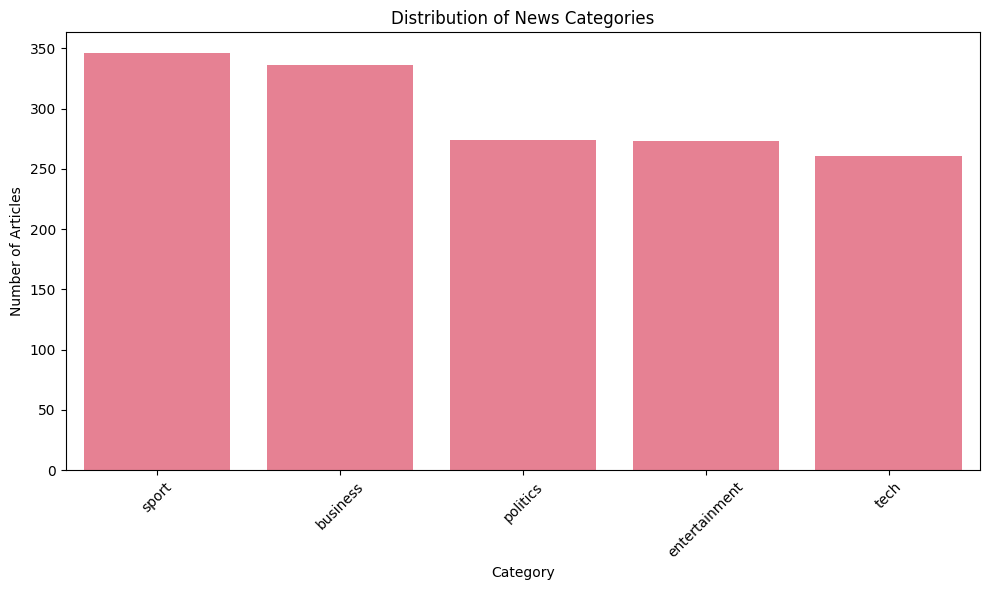

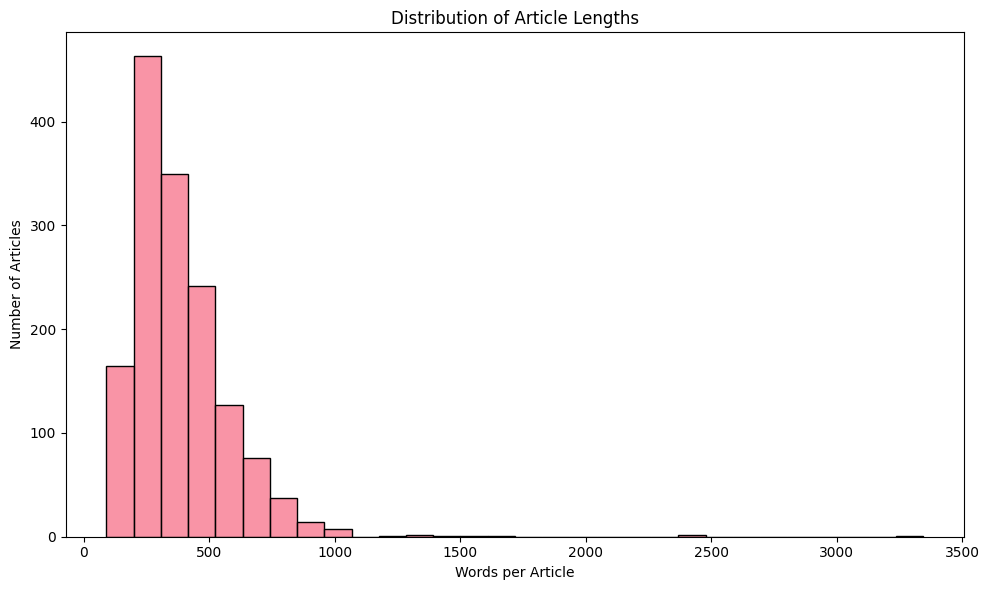

In [ ]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")

# Check data quality
print("\n🔍 MISSING VALUES")
print(df.isnull().sum())

print("\nDuplicate article IDs:", df['article_id'].duplicated().sum())
print("Duplicate texts:", df['content'].duplicated().sum())
print("Empty texts:", df['content'].str.strip().eq('').sum())

# Measure article length in words
df['word_count'] = df['content'].str.split().str.len()

print("\n📝 ARTICLE LENGTH IN WORDS")
print(df['word_count'].describe())

# Category distribution
print("\n📈 CATEGORY DISTRIBUTION")
category_counts = df['category'].value_counts()
print(category_counts)

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xlabel('Category')
plt.ylabel('Number of Articles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Text length distribution
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='word_count', bins=30)
plt.title('Distribution of Article Lengths')
plt.xlabel('Words per Article')
plt.ylabel('Number of Articles')
plt.tight_layout()
plt.show()

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [ ]:
# Initialize preprocessing tools
import html
nltk.download('punkt_tab')

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))


def clean_text(text):
    """Remove HTML, URLs, emails, symbols, digits, and extra spaces."""
    if pd.isna(text):
        return ""

    # Decode HTML entities and convert to lowercase
    text = html.unescape(str(text)).lower()

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', ' ', text)

    # Keep only letters and spaces
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text


def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """Clean, tokenize, optionally remove stopwords, and lemmatize."""
    text = clean_text(text)

    if not text:
        return ""

    # Tokenize
    tokens = word_tokenize(text)

    # Remove stopwords if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Apply basic WordNet lemmatization if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Remove words with fewer than three letters
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)


# Test the preprocessing functions
sample_text = (
    "Apple Inc. announced record quarterly earnings today! "
    "Visit https://apple.com for more info. #TechNews"
)

print("Original text:")
print(sample_text)

print("\nCleaned text:")
print(clean_text(sample_text))

print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [ ]:
# Remove duplicate articles before preprocessing
original_count = len(df)
df = df.drop_duplicates(subset='content').copy()
df = df.reset_index(drop=True)

print(f"Duplicate articles removed: {original_count - len(df)}")
print(f"Articles remaining: {len(df)}")

# Apply preprocessing
print("\n🧹 Preprocessing all articles...")

# Preserve original text and create processed versions
df['full_text'] = df['content']
df['content_clean'] = df['content'].apply(clean_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Keep the column expected by later notebook cells
df['full_text_processed'] = df['content_processed']

print("✅ Preprocessing complete!")

# Show before and after examples
print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)

for i in range(min(3, len(df))):
    print(f"\nExample {i + 1}:")
    print(f"Original: {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

# Compare text length in words
original_tokens = df['full_text'].str.split()
processed_tokens = df['full_text_processed'].str.split()

print("\n📊 PREPROCESSING RESULTS")
print(f"Average words before: {original_tokens.str.len().mean():.2f}")
print(f"Average words after: {processed_tokens.str.len().mean():.2f}")

# Count unique words, ignoring capitalization in the original text
words_before = Counter(
    word.lower()
    for tokens in original_tokens
    for word in tokens
)

words_after = Counter(
    word
    for tokens in processed_tokens
    for word in tokens
)

print(f"Unique words before: {len(words_before)}")
print(f"Unique words after: {len(words_after)}")

print("\nMost common words after preprocessing:")
print(words_after.most_common(15))

print(
    "\nEmpty processed articles:",
    df['full_text_processed'].str.strip().eq('').sum()
)

Duplicate articles removed: 50
Articles remaining: 1440

🧹 Preprocessing all articles...
✅ Preprocessing complete!

📝 BEFORE AND AFTER EXAMPLES

Example 1:
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a ba...
Processed: worldcom bos launch defence lawyer defending former worldcom chief bernie ebbers battery fraud charg...

Example 2:
Original: german business confidence slides german business confidence fell in february knocking hopes of a sp...
Processed: german business confidence slide german business confidence fell february knocking hope speedy recov...

Example 3:
Original: bbc poll indicates economic gloom citizens in a majority of nations surveyed in a bbc world service ...
Processed: bbc poll indicates economic gloom citizen majority nation surveyed bbc world service poll believe wo...

📊 PREPROCESSING RESULTS
Average words before: 385.22
Average words after: 209.69
Unique words before: 35594
Unique words after: 2064

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [ ]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1440, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.44%

🔍 Sample TF-IDF features:
   abbas  abc  ability  able  abroad  absence  absolute  absolutely  abuse  \
0    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
1    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
2    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   

   abused  
0     0.0  
1     0.0  
2     0.0  


In [ ]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category
# - Bar charts of top terms
# - Heatmap of term importance across categories

🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  firm: 0.0388
  company: 0.0371
  market: 0.0345
  year: 0.0329
  bank: 0.0326
  growth: 0.0325
  sale: 0.0316
  economy: 0.0314
  share: 0.0309
  profit: 0.0274

📰 TECH:
  mobile: 0.0522
  phone: 0.0472
  people: 0.0453
  game: 0.0400
  technology: 0.0400
  user: 0.0380
  service: 0.0354
  software: 0.0348
  computer: 0.0344
  net: 0.0335

📰 POLITICS:
  labour: 0.0639
  election: 0.0620
  blair: 0.0556
  party: 0.0523
  tory: 0.0459
  government: 0.0452
  would: 0.0447
  minister: 0.0425
  brown: 0.0381
  tax: 0.0329

📰 SPORT:
  game: 0.0449
  england: 0.0369
  win: 0.0337
  player: 0.0321
  match: 0.0317
  champion: 0.0289
  team: 0.0279
  cup: 0.0279
  final: 0.0263
  injury: 0.0256

📰 ENTERTAINMENT:
  film: 0.1015
  award: 0.0536
  best: 0.0477
  star: 0.0394
  show: 0.0378
  music: 0.0359
  actor: 0.0336
  band: 0.0333
  year: 0.0316
  oscar: 0.0304


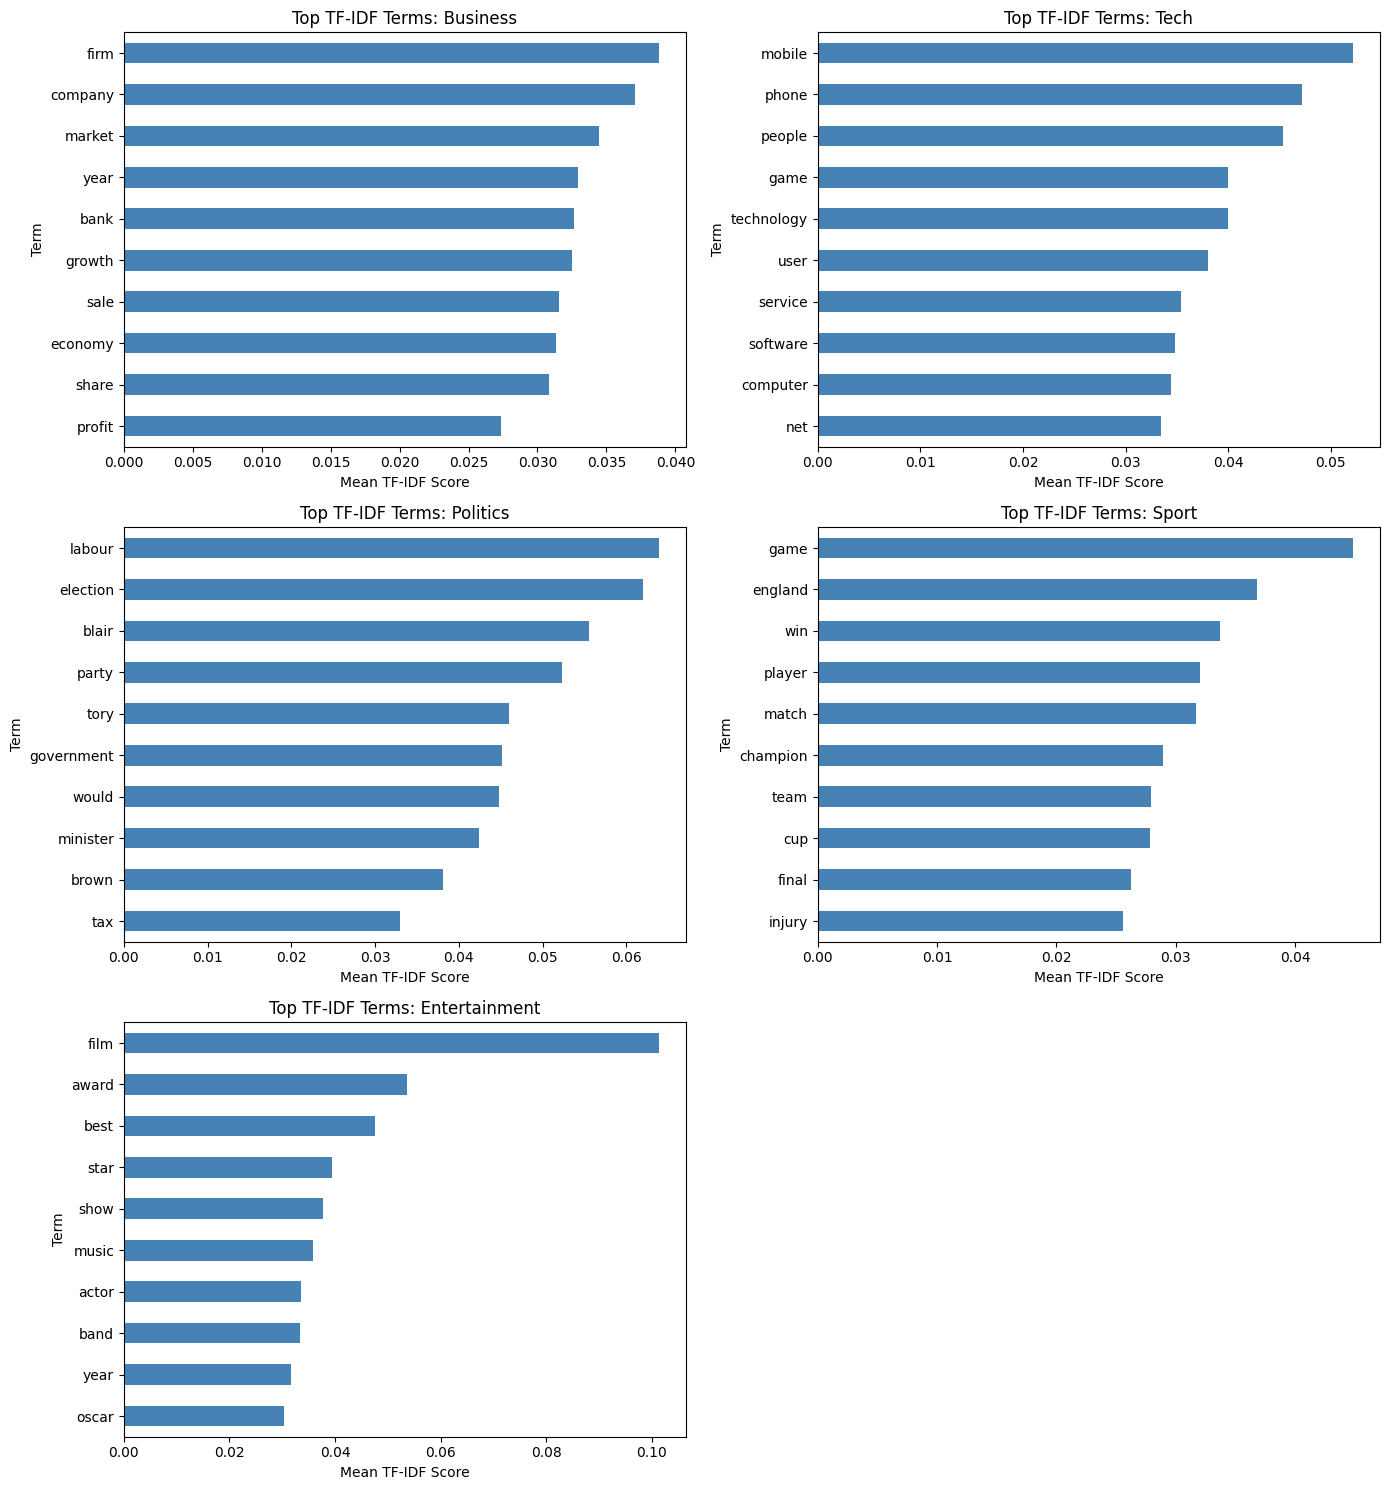

In [ ]:
# Plot the top TF-IDF terms for each category
fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for ax, (category, terms) in zip(axes, category_terms.items()):
    terms.sort_values().plot.barh(ax=ax, color='steelblue')
    ax.set_title(f"Top TF-IDF Terms: {category.title()}")
    ax.set_xlabel("Mean TF-IDF Score")
    ax.set_ylabel("Term")

# Hide unused panels
for ax in axes[len(category_terms):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [ ]:
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [ ]:
def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
         JJ       NNS        NN       VBG        IN        DT       VBP  \
0  0.088608  0.113924  0.231013  0.025316  0.110759  0.066456  0.015823   
1  0.119883  0.070175  0.233918  0.032164  0.134503  0.081871  0.014620   
2  0.079044  0.079044  0.200368  0.025735  0.119485  0.095588  0.016544   
3  0.083582  0.107463  0.156716  0.022388  0.122388  0.062687  0.041791   
4  0.089005  0.078534  0.212042  0.028796  0.123037  0.102094  0.015707   

        VBN      PRP$         .  ...   FW  SYM  WP$  NNP  NNPS  POS   UH    #  \
0  0.041139  0.012658  0.037975  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
1  0.029240  0.005848  0.040936  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
2  0.029412  0.016544  0.040441  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
3  0.017910  0.013433  0.046269  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
4  0.026178  0.015707  0.041885  ...

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
business       0.2240  0.0737  0.0011  0.0000  0.0333  0.0411  0.0200  0.0277   
entertainment  0.2453  0.0575  0.0007  0.0000  0.0283  0.0463  0.0193  0.0296   
politics       0.2089  0.0677  0.0007  0.0003  0.0454  0.0463  0.0209  0.0302   
sport          0.2184  0.0479  0.0005  0.0000  0.0407  0.0458  0.0175  0.0247   
tech           0.1930  0.0850  0.0007  0.0000  0.0421  0.0297  0.0237  0.0266   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
business       0.0158  0.0241  0.0920  0.0045  0.0033  0.0276  0.0018  0.0006   
entertainment  0.0179  0.0224  0.0939  0.0024  0.0050  0.0284  0.0010  0.0010   
politics       0.0199  0.0225  0.0901  0.0032  0

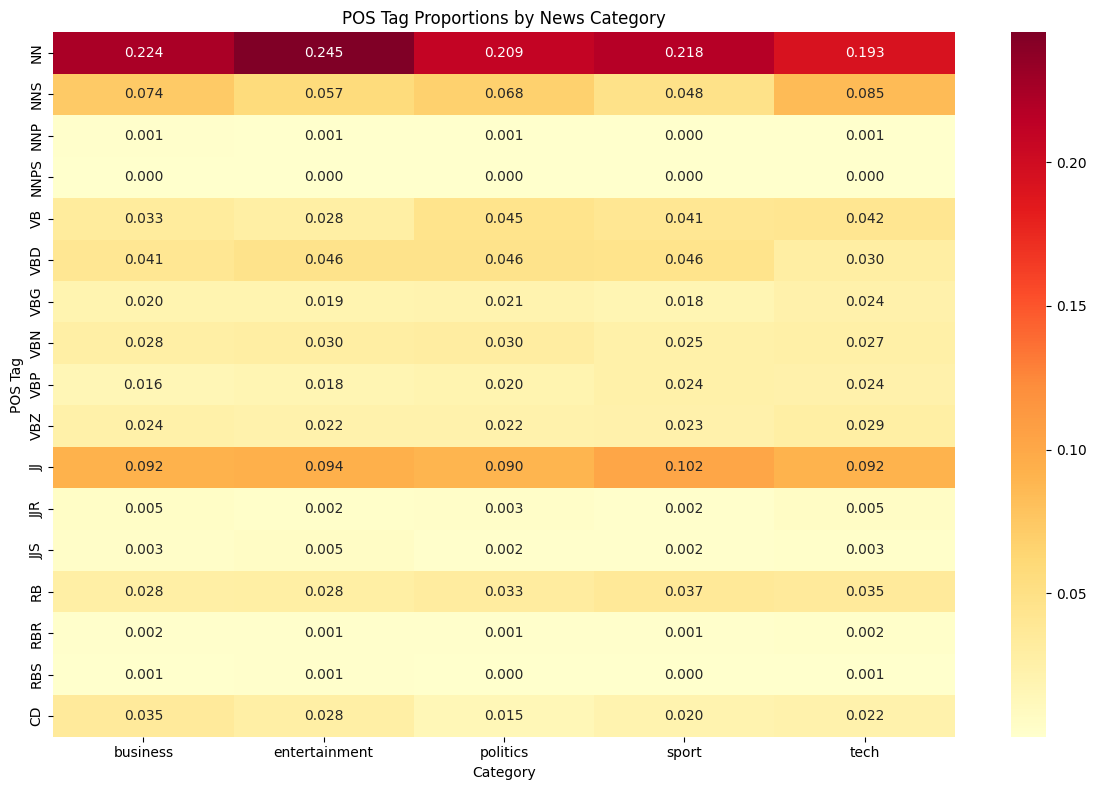


💡 ANALYSIS QUESTIONS:
1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
2. Which category uses the most action verbs (VB, VBD, VBG)?
3. Are there interesting patterns in adjective (JJ) usage?
4. How does number (CD) usage vary across categories?


In [ ]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = (
    pos_df.drop(columns='article_id')
    .groupby('category')
    .mean()
)

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Analyze the patterns
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?

    print("\n💡 ANALYSIS QUESTIONS:")
    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
    print("3. Are there interesting patterns in adjective (JJ) usage?")
    print("4. How does number (CD) usage vary across categories?")
else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [ ]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

        # Extract simple verb phrases: auxiliaries + verb + particles
    for token in doc:
        if token.pos_ == 'VERB':
            phrase_tokens = [
                child for child in token.children
                if child.dep_ in ['aux', 'auxpass', 'neg', 'prt']
            ]
            phrase_tokens.append(token)
            phrase_tokens.sort(key=lambda item: item.i)

            phrase = ' '.join(item.text for item in phrase_tokens)
            features['verb_phrases'].append(phrase.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3
    print(f"  Verb phrases: {result['verb_phrases'][:3]}...")

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (business):
  Sentences: 15
  Tokens: 346
  Noun phrases: ['-', 'boss', 'defence lawyers']...
  Subjects: ['-', 'boss', 'worldcom']...
  Objects: ['lawyers', 'ebbers', 'battery']...
  Verb phrases: ['launches', 'defending', 'have called']...

📰 Article 2 (business):
  Sentences: 15
  Tokens: 368
  Noun phrases: ['german business confidence', 'german business confidence', 'february']...
  Subjects: ['confidence', 'ifo', 'index']...
  Objects: ['confidence', 'february', 'hopes']...
  Verb phrases: ['slides', 'fell', 'knocking']...

📰 Article 3 (business):
  Sentences: 24
  Tokens: 587
  Noun phrases: ['bbc poll', 'economic gloom citizens', 'a majority']...
  Subjects: ['poll', 'citizens', 'economy']...
  Objects: ['majority', 'nations', 'poll']...
  Verb phrases: ['indicates', 'surveyed', 'believe']...

📰 Article 4 (tech):
  Sentences: 31
  Tokens: 724
  Noun phrases: ['lifestyle', 'mobile choice', 'faster  be

In [ ]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Select one sentence from the first article
article_doc = nlp(df.iloc[0]['content'])

# Choose a sentence with 8–25 words for readability
sample_sentence = next(
    (
        sent.text for sent in article_doc.sents
        if 8 <= len(sent) <= 25
    ),
    next(article_doc.sents).text
)

print(f"📝 Sample sentence: {sample_sentence}")

# Process the selected sentence
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# - Compare syntactic complexity across categories
# - Extract action patterns (who did what)
# - Identify most common dependency relations per category
# - Create features for classification based on syntax

📝 Sample sentence: worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002.

🌳 Dependency Parse Visualization:


## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [ ]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()


def analyze_sentiment(text):
    """Calculate VADER scores and assign a sentiment label."""
    if pd.isna(text) or not str(text).strip():
        return {
            'compound': 0.0,
            'pos': 0.0,
            'neu': 1.0,
            'neg': 0.0,
            'sentiment_label': 'neutral'
        }

    scores = sia.polarity_scores(str(text))

    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores


# Analyze original article text
print("😊 Analyzing sentiment...")

sentiment_results = []

for idx, row in df.iterrows():
    scores = analyze_sentiment(row['full_text'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        'content_sentiment': scores['compound'],
        'content_label': scores['sentiment_label'],
        'full_sentiment': scores['compound'],
        'full_label': scores['sentiment_label'],
        'pos_score': scores['pos'],
        'neu_score': scores['neu'],
        'neg_score': scores['neg']
    }

    sentiment_results.append(result)

sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")

print("\n📝 Sample sentiment results:")
print(
    sentiment_df[
        ['category', 'full_sentiment', 'full_label']
    ].head()
)

😊 Analyzing sentiment...
✅ Sentiment analysis complete!
📊 Analyzed 1440 articles

📝 Sample sentiment results:
   category  full_sentiment full_label
0  business         -0.9701   negative
1  business          0.7623   positive
2  business         -0.9318   negative
3      tech          0.9554   positive
4  business         -0.9486   negative


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
business              0.2381  0.8372 -0.9985  0.9995    0.0924    0.8371   
entertainment         0.5900  0.6865 -0.9978  0.9999    0.1362    0.8093   
politics              0.0541  0.8798 -0.9984  0.9999    0.0946    0.8183   
sport                 0.5492  0.7272 -0.9967  0.9996    0.1355    0.7938   
tech                  0.5330  0.7479 -0.9991  0.9993    0.0898    0.8598   

              neg_score  
                   mean  
category                 
business         0.0705  
entertainment    0.0545  
politics         0.0871  
sport            0.0707  
tech             0.0504  

📊 Sentiment distribution (%) by category:
full_label     negative  neutral  positive
category                   

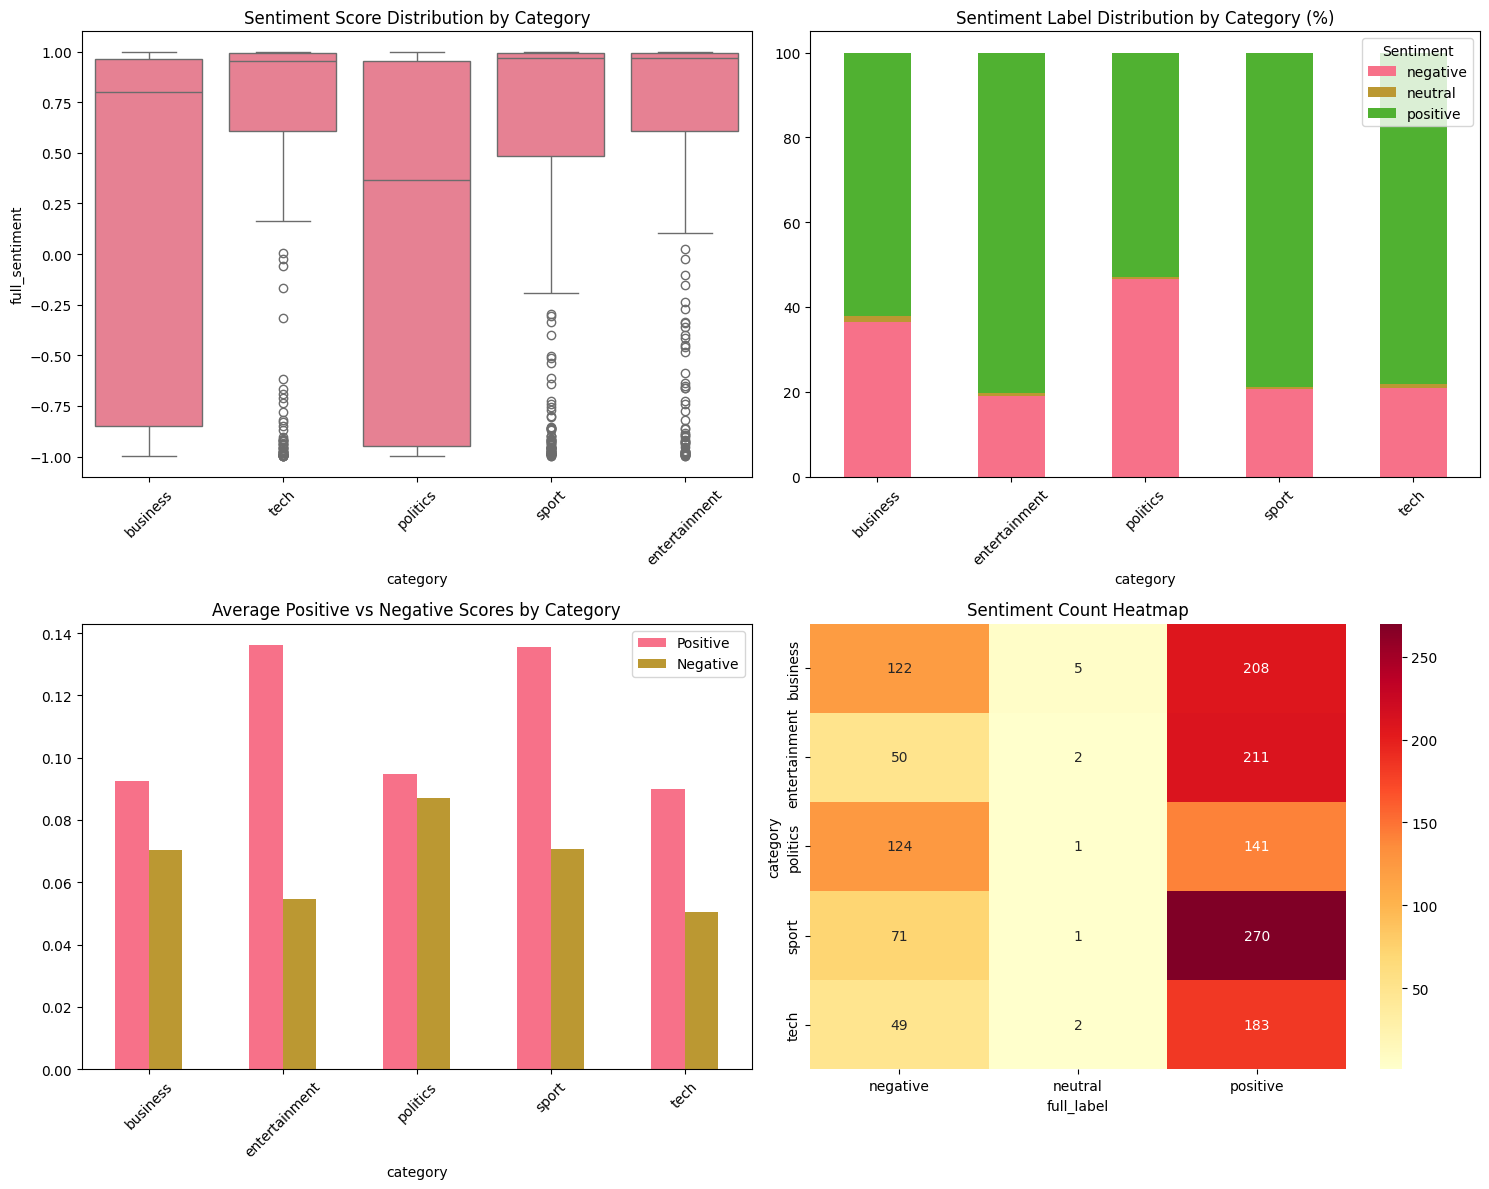

In [ ]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Analyze sentiment patterns
# - Which categories are most positive/negative?
# - Are there differences between title and content sentiment?
# - How does sentiment vary within categories?
# - Can sentiment be used as a feature for classification?

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# Match sentiment scores to articles by ID
sentiment_columns = [
    'article_id',
    'full_sentiment',
    'pos_score',
    'neu_score',
    'neg_score'
]

classification_df = df[
    ['article_id', 'full_text', 'full_text_processed', 'category']
].merge(
    sentiment_df[sentiment_columns],
    on='article_id',
    how='left',
    validate='one_to_one'
)

# Add text length features
classification_df['char_count'] = (
    classification_df['full_text'].str.len()
)
classification_df['word_count'] = (
    classification_df['full_text'].str.split().str.len()
)

# Keep text and numeric features together
numeric_features = [
    'full_sentiment', 'pos_score', 'neu_score', 'neg_score',
    'char_count', 'word_count'
]

X_combined = classification_df[
    ['full_text_processed'] + numeric_features
].copy()

y = classification_df['category'].values

# Check that all features are available
assert not X_combined.isna().any().any(), "Missing feature values"

# Split BEFORE fitting TF-IDF or scaling numeric features
X_train, X_test, y_train, y_test = train_test_split(
    X_combined,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("✅ Data prepared!")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

print("\n📈 Data split:")
print(f"  Training set: {len(X_train)} samples")
print(f"  Test set: {len(X_test)} samples")

🔧 Preparing features for classification...
✅ Data prepared!
🎯 Number of classes: 5
📋 Classes: ['business' 'entertainment' 'politics' 'sport' 'tech']

📈 Data split:
  Training set: 1152 samples
  Test set: 288 samples


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.base import clone

print("🤖 Training multiple classifiers...")

# Convert compound sentiment from [-1, 1] to [0, 1]
# This fixed transformation does not learn from the test data
X_train = X_train.copy()
X_test = X_test.copy()

X_train['full_sentiment'] = (
    X_train['full_sentiment'] + 1
) / 2

X_test['full_sentiment'] = (
    X_test['full_sentiment'] + 1
) / 2

# Preprocessing learned within each training fold
feature_processor = ColumnTransformer(
    transformers=[
        (
            'text',
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.8
            ),
            'full_text_processed'
        ),
        (
            'numeric',
            MinMaxScaler(clip=True),
            numeric_features
        )
    ]
)

classifiers = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(
        random_state=42,
        max_iter=1000
    ),
    'SVM': SVC(
        kernel='linear',
        random_state=42,
        probability=True
    )
}

results = {}
trained_models = {}

for name, classifier in classifiers.items():
    print(f"\n🔄 Training {name}...")

    model = Pipeline([
        ('features', clone(feature_processor)),
        ('classifier', classifier)
    ])

    # Cross-validation uses only the training set
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=3,
        scoring='accuracy'
    )

    # Fit on the complete training set
    model.fit(X_train, y_train)

    # Evaluate on the held-out test set
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = model

    print(f"  ✅ Test accuracy: {accuracy:.4f}")
    print(f"  📊 CV accuracy: {cv_scores.mean():.4f}")
    print(f"  📉 CV standard deviation: {cv_scores.std():.4f}")

comparison_df = pd.DataFrame([
    {
        'Model': name,
        'Test Accuracy': values['accuracy'],
        'CV Mean': values['cv_mean'],
        'CV Std': values['cv_std']
    }
    for name, values in results.items()
])

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
print(comparison_df.round(4))

# Select using training cross-validation, not test accuracy
best_model_name = comparison_df.loc[
    comparison_df['CV Mean'].idxmax(), 'Model'
]

print(f"\n🥇 Best model by CV accuracy: {best_model_name}")

🤖 Training multiple classifiers...

🔄 Training Naive Bayes...
  ✅ Test accuracy: 0.9375
  📊 CV accuracy: 0.9549
  📉 CV standard deviation: 0.0117

🔄 Training Logistic Regression...
  ✅ Test accuracy: 0.9410
  📊 CV accuracy: 0.9453
  📉 CV standard deviation: 0.0056

🔄 Training SVM...
  ✅ Test accuracy: 0.9583
  📊 CV accuracy: 0.9679
  📉 CV standard deviation: 0.0065

🏆 CLASSIFIER COMPARISON
                 Model  Test Accuracy  CV Mean  CV Std
0          Naive Bayes         0.9375   0.9549  0.0117
1  Logistic Regression         0.9410   0.9453  0.0056
2                  SVM         0.9583   0.9679  0.0065

🥇 Best model by CV accuracy: SVM


📊 DETAILED EVALUATION: SVM

📋 Classification Report:
               precision    recall  f1-score   support

     business       0.94      0.99      0.96        67
entertainment       0.98      0.94      0.96        53
     politics       0.96      0.94      0.95        53
        sport       0.94      1.00      0.97        68
         tech       0.98      0.89      0.93        47

     accuracy                           0.96       288
    macro avg       0.96      0.95      0.96       288
 weighted avg       0.96      0.96      0.96       288



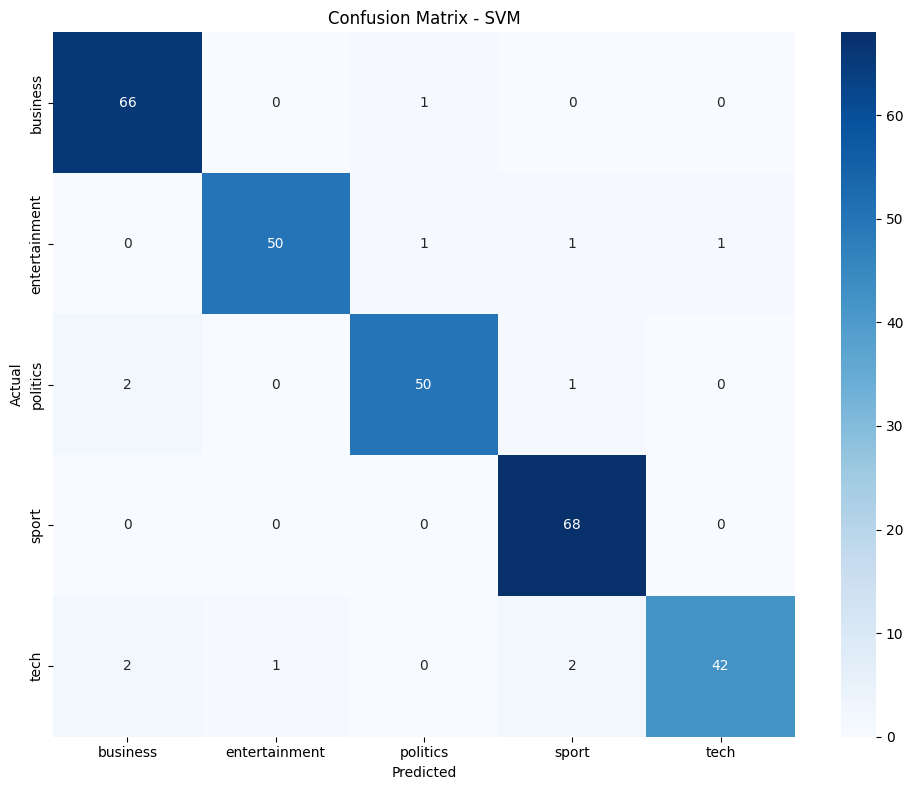


🔍 The linear SVM uses pairwise classifiers. Each coefficient row compares two categories.
Per-category feature rankings require additional analysis; they cannot be read as one coefficient row per category.


In [ ]:
# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']
class_labels = best_model.classes_

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=class_labels,
    zero_division=0
))

# Confusion matrix with explicit category order
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=class_labels
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Inspect coefficients from the fitted pipeline
classifier = best_model.named_steps['classifier']
processor = best_model.named_steps['features']

if best_model_name == 'Logistic Regression':
    fitted_feature_names = processor.get_feature_names_out()
    coefficients = classifier.coef_

    print("\n🔍 Highest Positive Coefficients by Category:")

    for i, class_name in enumerate(classifier.classes_):
        top_indices = np.argsort(coefficients[i])[-10:][::-1]

        print(f"\n📰 {class_name}:")
        for idx in top_indices:
            print(
                f"  {fitted_feature_names[idx]}: "
                f"{coefficients[i, idx]:.4f}"
            )

elif best_model_name == 'SVM':
    print(
        "\n🔍 The linear SVM uses pairwise classifiers. "
        "Each coefficient row compares two categories."
    )
    print(
        "Per-category feature rankings require additional analysis; "
        "they cannot be read as one coefficient row per category."
    )

# Student task:
# Compare feature combinations and tune parameters using
# cross-validation on training data, keeping the test set fixed.

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [ ]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
    entities = extract_entities(row['full_text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 40803
📰 Articles processed: 1440

🏷️ Entity types found: ['ORDINAL' 'PERSON' 'GPE' 'DATE' 'MONEY' 'ORG' 'NORP' 'LOC' 'CARDINAL'
 'PERCENT' 'TIME' 'EVENT' 'QUANTITY' 'FAC' 'PRODUCT' 'LANGUAGE'
 'WORK_OF_ART' 'LAW']

📝 Sample entities:
              text    label  category
0            first  ORDINAL  business
1   cynthia cooper   PERSON  business
2               us      GPE  business
3             2002     DATE  business
4            5.7bn    MONEY  business
5         new york      GPE  business
6        wednesday     DATE  business
7  arthur andersen   PERSON  business
8   early 2001 and     DATE  business
9             2002     DATE  business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE           8523
PERSON         7802
CARDINAL       5965
GPE            5433
ORG            4288
NORP           2666
MONEY          1710
ORDINAL        1609
PERCENT        1242
TIME            582
LOC             489
QUANTITY        191
FAC              88
PRODUCT          82
LANGUAGE         50
EVENT            42
LAW              33
WORK_OF_ART       8
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC   GPE  LANGUAGE  LAW  LOC  MONEY  \
category                                                                     
business           1031  2398      3   10  1543         1   15  166    906   
entertainment      1068  1672     11   15   773         9    4   63    343   
politics            804  1322     22   23   933        10    4  120    222   
sport              1780  1966      5   39  1482        11    5   33     43   
tech               1282  1165      1    1   702     

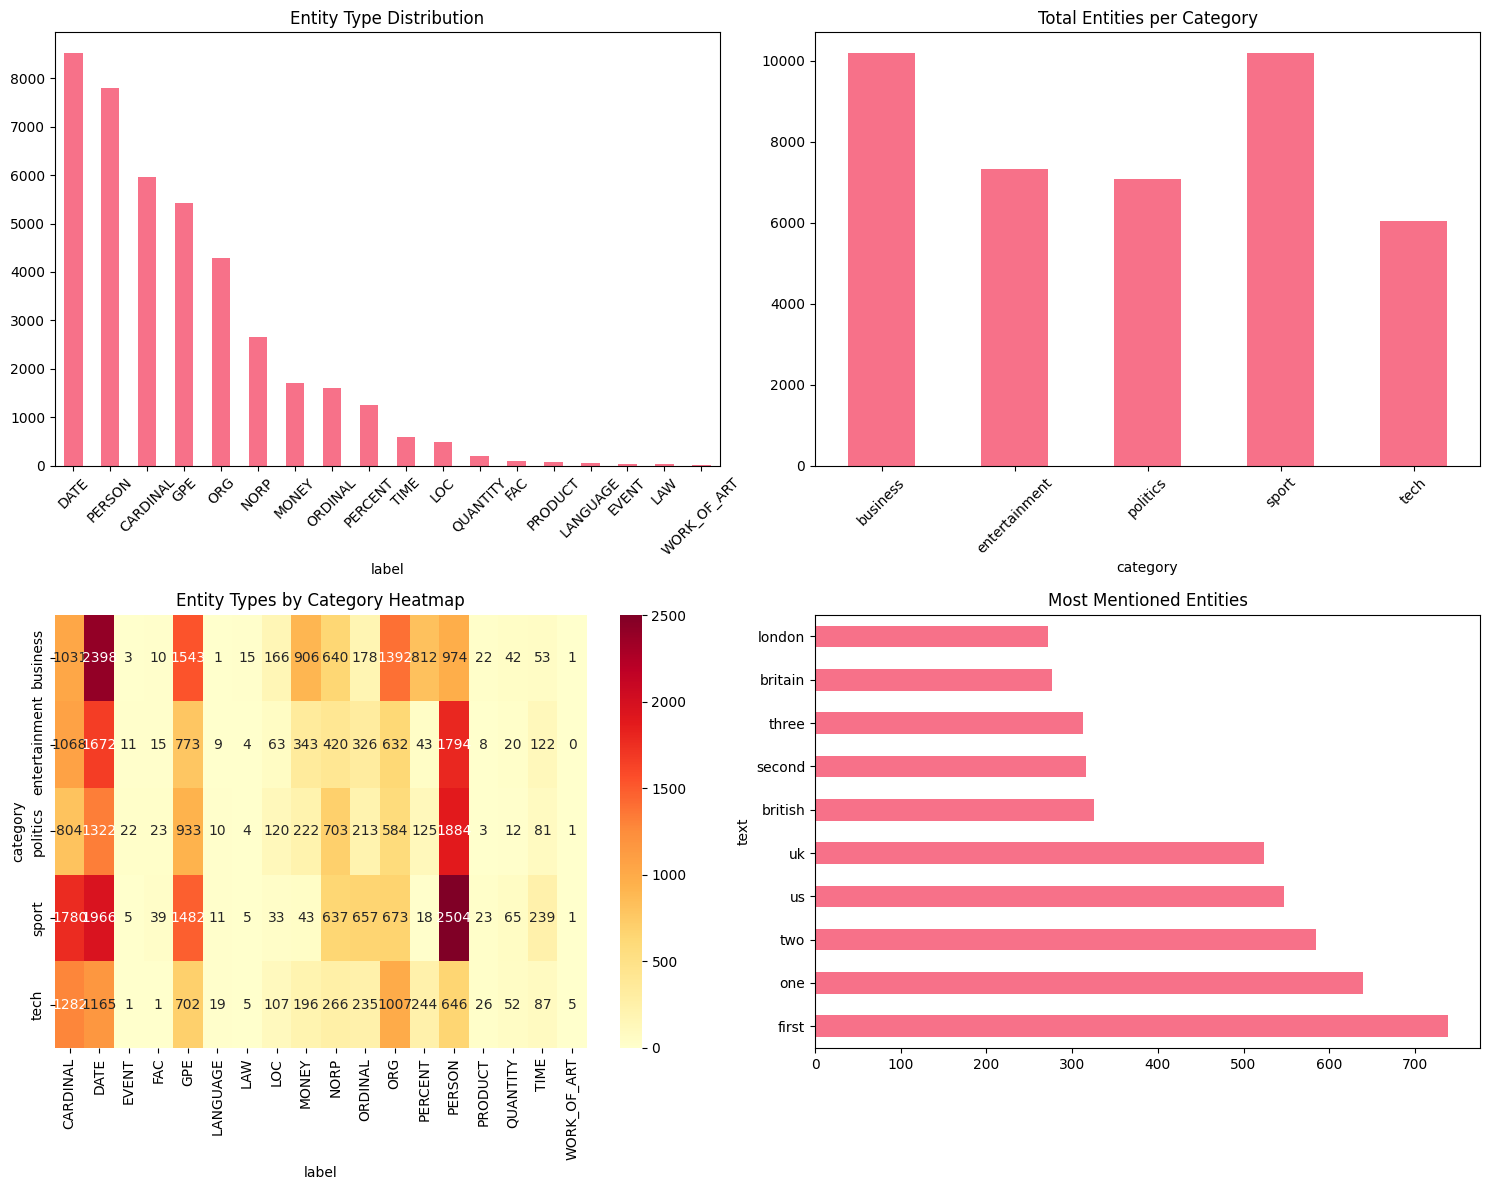

In [ ]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [ ]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

    # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean()
    }

    # Classification performance
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append(
    "✅ Strong results on the BBC test set support a pilot "
    "for content routing, with human review and testing on newer articles."
    )
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(
    f"📊 {pos_cat} has the highest average VADER sentiment "
    "in this dataset."
    )
    recommendations.append(
    f"📊 {neg_cat} has the lowest average VADER sentiment "
    "in this dataset; this alone does not establish media bias."
    )
    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append(
    "🔍 Entity extraction can support search and mention tracking; "
    "labels require review, and relationship analysis needs additional processing."
    )

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 1440
  Categories: business, tech, politics, sport, entertainment
  Average Article Length: 2234 characters
  Average Words per Article: 385 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: SVM
  Best Accuracy: 0.9583

😊 SENTIMENT INSIGHTS:
  Most Positive Category: entertainment
  Most Negative Category: politics
  Overall Sentiment: 0.3902

🔍 ENTITY INSIGHTS:
  Total Entities: 40803
  Unique Entities: 12071
  Entity Types: ORDINAL, PERSON, GPE, DATE, MONEY, ORG, NORP, LOC, CARDINAL, PERCENT, TIME, EVENT, QUANTITY, FAC, PRODUCT, LANGUAGE, WORK_OF_ART, LAW

💡 BUSINESS RECOMMENDATIONS:
  1. ✅ Strong results on the BBC test set support a pilot for content routing, with human review and testing on newer articles.
  2. 📊 entertainment has the highest average VADER sentiment in this dataset.
  3. 📊 politics has the lowest average VADER se

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [ ]:
class NewsBotIntelligenceSystem:
    """Integrated prototype for news classification and analysis."""

    def __init__(self, classifier, sentiment_analyzer):
        self.classifier = classifier
        self.sentiment_analyzer = sentiment_analyzer

    def preprocess_article(self, title, content):
        """Combine inputs and apply the training preprocessing."""
        full_text = f"{title} {content}".strip()

        if not full_text:
            raise ValueError("Please provide an article title or content.")

        processed_text = preprocess_text(full_text)

        if not processed_text:
            raise ValueError(
                "No usable words remain after preprocessing."
            )

        return full_text, processed_text

    def analyze_sentiment(self, text):
        """Calculate VADER sentiment with consistent thresholds."""
        scores = self.sentiment_analyzer.polarity_scores(text)

        if scores['compound'] >= 0.05:
            scores['sentiment_label'] = 'positive'
        elif scores['compound'] <= -0.05:
            scores['sentiment_label'] = 'negative'
        else:
            scores['sentiment_label'] = 'neutral'

        return scores

    def classify_article(self, full_text, processed_text, sentiment):
        """Build the same input features used during training."""
        features = pd.DataFrame([{
            'full_text_processed': processed_text,

            # Apply the same fixed transformation used in training
            'full_sentiment': (sentiment['compound'] + 1) / 2,

            'pos_score': sentiment['pos'],
            'neu_score': sentiment['neu'],
            'neg_score': sentiment['neg'],
            'char_count': len(full_text),
            'word_count': len(full_text.split())
        }])

        # The fitted pipeline handles TF-IDF and numeric scaling
        prediction = self.classifier.predict(features)[0]
        probabilities = self.classifier.predict_proba(features)[0]

        class_probs = {
            label: float(probability)
            for label, probability in zip(
                self.classifier.classes_, probabilities
            )
        }

        return prediction, class_probs

    def extract_entities(self, text):
        """Extract entity mentions using the existing function."""
        return extract_entities(text)

    def process_article(self, title, content):
        """Process a new article through the integrated system."""
        if not isinstance(title, str) or not isinstance(content, str):
            raise TypeError("Title and content must be strings.")

        # Preprocess and calculate real sentiment features
        full_text, processed_text = self.preprocess_article(
            title, content
        )
        sentiment = self.analyze_sentiment(full_text)

        # Predict category and extract entity mentions
        category, category_probs = self.classify_article(
            full_text, processed_text, sentiment
        )
        entities = self.extract_entities(full_text)

        # Probability assigned to the predicted class
        confidence = category_probs[category]

        insights = self.generate_insights(
            category, entities, sentiment, category_probs
        )

        return {
            'title': title,
            'content': (
                content[:200] + '...'
                if len(content) > 200 else content
            ),
            'predicted_category': category,
            'category_confidence': confidence,
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(
        self, category, entities, sentiment, category_probs
    ):
        """Summarize predictions without treating them as facts."""
        confidence = category_probs[category]

        insights = [
            f"Predicted category: {category}. "
            f"Estimated class probability: {confidence:.2%}.",
            "Class probabilities are model estimates, "
            "not guarantees of correctness."
        ]

        # Operational review threshold, not a validated guarantee
        if confidence < 0.8:
            insights.append(
                "Consider manual review under the prototype's "
                "0.80 review threshold."
            )

        # Use the same sentiment label as the analysis function
        insights.append(
            f"VADER article tone: {sentiment['sentiment_label']} "
            f"(compound score: {sentiment['compound']:.3f})."
        )

        if entities:
            entity_types = {entity['label'] for entity in entities}

            insights.append(
                f"Detected {len(entities)} entity mentions "
                f"across {len(entity_types)} types."
            )

            # Show distinct important entity texts
            key_entities = list(dict.fromkeys(
                entity['text']
                for entity in entities
                if entity['label'] in ['PERSON', 'ORG', 'GPE']
            ))[:3]

            if key_entities:
                insights.append(
                    f"Example entity mentions: {', '.join(key_entities)}."
                )
        else:
            insights.append("No named entities detected.")

        return insights


# Initialize using the fitted classification pipeline
newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    sentiment_analyzer=sia
)

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Prototype ready to test on new articles")

🤖 NewsBot Intelligence System initialized!
✅ Prototype ready to test on new articles


In [ ]:
# Test the complete system with synthetic articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Synthetic examples, not verified news reports
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': (
            'Microsoft Corporation announced today the acquisition of '
            'an artificial intelligence startup for $2 billion. '
            'CEO Satya Nadella said the deal will strengthen '
            "Microsoft's position in the AI market and enhance "
            'its cloud computing services.'
        )
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': (
            'The Los Angeles Lakers defeated the Boston Celtics '
            '108-102 in overtime to win the NBA championship. '
            'LeBron James scored 35 points and was named Finals MVP.'
        )
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': (
            'Scientists at the United Nations released a comprehensive '
            'climate report showing accelerating global warming. '
            'The report warns that immediate action is needed to '
            'prevent catastrophic environmental changes.'
        )
    }
]

for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    result = newsbot.process_article(
        article['title'],
        article['content']
    )

    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")

    print(
        f"\n🏷️ Predicted Category: {result['predicted_category']} "
        f"(estimated probability: "
        f"{result['category_confidence']:.2%})"
    )

    print("\n📊 Category Probabilities:")
    for category, probability in sorted(
        result['category_probabilities'].items(),
        key=lambda item: item[1],
        reverse=True
    ):
        print(f"  {category}: {probability:.3f}")

    print(
        f"\n😊 Sentiment: "
        f"{result['sentiment']['sentiment_label']} "
        f"(score: {result['sentiment']['compound']:.3f})"
    )

    if result['entities']:
        print(f"\n🔍 Entity Mentions ({len(result['entities'])}):")

        for entity in result['entities'][:5]:
            print(
                f"  {entity['text']} ({entity['label']}) "
                f"- {entity['description']}"
            )
    else:
        print("\n🔍 No entities detected")

    print("\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 Testing complete!")
print("All three synthetic examples were processed.")
print("Review the predictions; execution success is not accuracy.")

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: tech (estimated probability: 59.02%)

📊 Category Probabilities:
  tech: 0.590
  business: 0.253
  entertainment: 0.065
  politics: 0.059
  sport: 0.033

😊 Sentiment: positive (score: 0.660)

🔍 Entity Mentions (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  Predicted category: tech. Estimated class probability: 59.02%.
  Class prob

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
   - The most challenging part of the colab was combining TF-IDF, sentiment scores, and text length features for classification. The dependency parsing was also challenging because, some results were incorrect or difficult to interpret. TF-IDF and classification were the most useful techniques because they help the system to organize the articles into categories.
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
   - I combined NLP tasks keeping the original text for sentiment analysis, entities, and grammatical analysis, while I am creating a processed version for classification. I adapted the notebook to the BBC dataset because it did not have separate title, date, or source columns. I also used a pipeline to fit TF-IDF and scale numerical features using only training data.
3. **Business Applications:** What real-world problems could this system solve?
   - This system could help news websites organize articles and help companies to monitor mentions of their names. Could also support searches for people, organizations, and locations. Human review would still be necessary for ambiguous articles and incorrect predictions.
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
   - Automated news analysis can assign incorrect categories, sentiment labels, or entity types. For example, the system labeled the climate example as positive even though it contained warnings. Users should understand that these outputs are estimates and should not treat them as verified facts or proof of media bias.
5. **Future Learning:** What NLP topics are you most excited to explore next?
   - I would like to learn more about transformer models such as BERT and how they handle the context and ambiguous language. I am also interested in improving entity recognition and distinguishing specific emotions like positive, negative, and neutral sentiment.
6. **Team Collaboration:** How did you divide work and ensure quality?
   - I completed this project individually, so I was responsible for every section. I organized the work by module, ran the cells in order, and reviewed the outputs before continuing. When I encountered errors, I checked the code and made adjustments to match the dataset and the trained pipeline.
7. **Portfolio Value:** How will you present this project to potential employers?
   - I plan to present this project in my GitHub portfolio with the notebook, setup instructions, visualizations, and an explanation of the results. I would highlight that SVM achieved 95.83% accuracy on the BBC test split. I would also explain the limitations found when testing new examples, including ambiguous categories and errors in sentiment and entity recognition.
---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*